# Notebook 3 – ETS Forecasting and Final Statistical Comparison

## Group Members
- Student 1: `[Bea Nº2170307]`
- Student 2: `[João Coelho Nº2200881]`

## Objective
This notebook implements **Phase 3** of the project using an **ETS (Error, Trend, Seasonality)** model for retail demand forecasting.

The goal is to:
1. Load the same cleaned panel used in the previous notebooks;
2. Train and validate an ETS model under the same chronological split;
3. Evaluate performance with **MAE, RMSE, and RMSSE**;
4. Compare ETS against the previously developed **Baselines** and **ARIMA / AutoARIMA** models;
5. Export the final consolidated results for the full statistical-model pipeline.

To ensure a **fair and professional comparison**, this notebook reuses the same temporal split and evaluation framework as the earlier notebooks.

## 0. Optional Google Drive Persistence

This small setup cell keeps the notebook workflow unchanged while saving CSV outputs to a persistent Google Drive folder when running in Colab. If Google Drive is not available, the notebook falls back to the current working directory.


In [14]:
import os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE_PATH = "/content/drive/MyDrive/m5_project"
    os.makedirs(BASE_PATH, exist_ok=True)
    print(f"Google Drive connected. Files will also be saved to: {BASE_PATH}")
except Exception:
    BASE_PATH = "."
    print("Google Drive not available. Using the current working directory.")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Google Drive connected. Files will also be saved to: /content/drive/MyDrive/m5_project


In [15]:
!pip install statsforecast pyarrow statsmodels

In [16]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.graphics.tsaplots import plot_acf

from statsforecast import StatsForecast
from statsforecast.models import AutoETS

print("Libraries loaded successfully.")

Libraries loaded successfully.


## 1.Load the Data

The preferred input for this notebook is the cleaned dataset exported from the previous stage, typically named `m5_clean.csv`.

However, for robustness and reproducibility, the notebook also includes a fallback option:
- if `m5_clean.csv` exists, it is used directly;
- otherwise, the original M5 parquet files are reloaded and the same department-store panel is rebuilt.

This makes the notebook more reliable and easier to run independently.

In [17]:
# LOAD DATA EXPORTED FROM PREVIOUS NOTEBOOKS

drive_clean_path = f"{BASE_PATH}/m5_clean.csv"
local_clean_path = "m5_clean.csv"

if os.path.exists(drive_clean_path):
    clean_path = drive_clean_path
elif os.path.exists(local_clean_path):
    clean_path = local_clean_path
else:
    raise FileNotFoundError(
        "m5_clean.csv not found in Google Drive or local storage. Please export it from the Baselines notebook first."
    )

df = pd.read_csv(clean_path)
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

print(f"Loaded cleaned dataset from: {clean_path}")
print("Shape:", df.shape)
print("Unique series:", df["unique_id"].nunique())
print("Date range:", df["ds"].min(), "to", df["ds"].max())


Loaded cleaned dataset from: /content/drive/MyDrive/m5_project/m5_clean.csv
Shape: (370418, 3)
Unique series: 216
Date range: 2011-01-29 00:00:00 to 2016-06-19 00:00:00


## 2.Recreate the Chronological Split

The same split used in the Baselines and ARIMA notebooks is reproduced here.

- **Training set**: all observations before 25 April 2016  
- **Validation set**: 25 April 2016 to 22 May 2016  
- **Test set**: from 23 May 2016 onward  

The **28-day validation horizon** mirrors the M5 competition setting and ensures direct comparability across all statistical models.

In [18]:
df = df.sort_values(["unique_id", "ds"]).reset_index(drop=True)

test_start = pd.Timestamp("2016-05-23")
val_start  = pd.Timestamp("2016-04-25")
val_end    = pd.Timestamp("2016-05-22")

train_main = df[df["ds"] < val_start].copy()
val        = df[(df["ds"] >= val_start) & (df["ds"] <= val_end)].copy()
test       = df[df["ds"] >= test_start].copy()

print("Train shape:", train_main.shape)
print("Validation shape:", val.shape)
print("Test shape:", test.shape)

print("\nUnique series in train:", train_main["unique_id"].nunique())
print("Unique series in validation:", val["unique_id"].nunique())
print("Unique series in test:", test["unique_id"].nunique())

# quick integrity checks
expected_h = 28
val_counts = val["unique_id"].astype(str).value_counts()
print("\nValidation horizon per series:")
print(val_counts.describe())

assert val_counts.min() == expected_h and val_counts.max() == expected_h, "Each series should have exactly 28 validation points."

Train shape: (358322, 3)
Validation shape: (6048, 3)
Test shape: (6048, 3)

Unique series in train: 216
Unique series in validation: 216
Unique series in test: 216

Validation horizon per series:
count    216.0
mean      28.0
std        0.0
min       28.0
25%       28.0
50%       28.0
75%       28.0
max       28.0
Name: count, dtype: float64


## 3.Evaluation Metrics

To evaluate ETS rigorously and keep consistency with the earlier notebooks, we use:

- **MAE**: average absolute forecasting error;
- **RMSE**: penalises larger errors more strongly;
- **RMSSE**: a scaled metric particularly relevant for M5-style retail forecasting, since it normalises error using the historical variation of each time series.

RMSSE is especially important because it allows a more balanced comparison across multiple product series with different sales levels.

In [19]:
def mae(actual, pred):
    return mean_absolute_error(actual, pred)

def rmse(actual, pred):
    return np.sqrt(mean_squared_error(actual, pred))

def rmsse_per_series(train_series, actual, pred):
    train_series = np.asarray(train_series)
    actual = np.asarray(actual)
    pred = np.asarray(pred)

    denom = np.mean(np.diff(train_series) ** 2)
    if denom == 0 or np.isnan(denom):
        return np.nan
    return np.sqrt(np.mean((actual - pred) ** 2) / denom)

def evaluate_panel(train_df, actual_df, forecast_df, model_col):
    merged = actual_df.merge(
        forecast_df[["unique_id", "ds", model_col]],
        on=["unique_id", "ds"],
        how="left"
    )

    assert merged.shape[0] == actual_df.shape[0], "Merge mismatch: some actual observations were lost."
    assert merged[model_col].isna().sum() == 0, f"Missing forecasts detected in {model_col}."

    mae_val = mae(merged["y"], merged[model_col])
    rmse_val = rmse(merged["y"], merged[model_col])

    rmsse_list = []
    for uid in merged["unique_id"].unique():
        train_series = train_df.loc[train_df["unique_id"] == uid, "y"].values
        actual_series = merged.loc[merged["unique_id"] == uid, "y"].values
        pred_series = merged.loc[merged["unique_id"] == uid, model_col].values
        rmsse_list.append(rmsse_per_series(train_series, actual_series, pred_series))

    rmsse_val = np.nanmean(rmsse_list)
    return mae_val, rmse_val, rmsse_val, merged

## 4.Why ETS?

ETS models are powerful classical forecasting models that explicitly decompose time series into:

- **Error**
- **Trend**
- **Seasonality**

This makes ETS especially suitable when:
- level changes over time,
- trend may be present,
- recurrent seasonal behaviour exists.

In this project, weekly seasonality was already identified in the exploratory analysis.  
Therefore, ETS is a strong candidate, particularly as a benchmark against both simpler baselines and ARIMA-based methods.

In [20]:
# AutoETS automatically selects the best ETS configuration.
# season_length=7 captures the weekly seasonality observed in the data.
ets_model = AutoETS(season_length=7, model="ZZZ")

sf_ets = StatsForecast(
    models=[ets_model],
    freq="D",
    n_jobs=-1
)

print("Training AutoETS...")
sf_ets.fit(train_main)

print("Generating validation forecasts...")
fcst_ets_val = sf_ets.forecast(df=train_main, h=28, level=[95])

display(fcst_ets_val.head())

Training AutoETS...
Generating validation forecasts...


,unique_id,ds,AutoETS,AutoETS-lo-95,AutoETS-hi-95
0,FOODS_1_001_TX_1,2016-04-25,0.365621,-2.200825,2.932068
1,FOODS_1_001_TX_1,2016-04-26,0.365621,-2.201339,2.932582
2,FOODS_1_001_TX_1,2016-04-27,0.365621,-2.201853,2.933096
3,FOODS_1_001_TX_1,2016-04-28,0.365621,-2.202367,2.933610
4,FOODS_1_001_TX_1,2016-04-29,0.365621,-2.202880,2.934123


## 5.ETS Validation Performance

The model is evaluated over the 28-day validation horizon using the same metric framework as before.

This ensures that any improvement or deterioration in performance reflects the model itself rather than differences in preprocessing or evaluation design.

In [21]:
ets_mae, ets_rmse, ets_rmsse, ets_eval_df = evaluate_panel(
    train_main,
    val,
    fcst_ets_val,
    "AutoETS"
)

ets_metrics_df = pd.DataFrame([{
    "Model": "AutoETS",
    "MAE": ets_mae,
    "RMSE": ets_rmse,
    "RMSSE": ets_rmsse
}])

print("ETS validation metrics:")
display(ets_metrics_df)

ETS validation metrics:


,Model,MAE,RMSE,RMSSE
0,AutoETS,1.06343,2.053841,0.745743


## 6.Diagnostics and Forecast Interpretation

A good forecasting model should leave residuals that resemble **white noise**, meaning that most systematic structure has already been captured.

To inspect the ETS behaviour, we:
1. Visualise actual vs forecast values for one representative series;
2. Plot residuals;
3. Inspect the residual ACF.

These plots are shown for **one representative series**, while performance metrics were computed across the **full panel of series**.

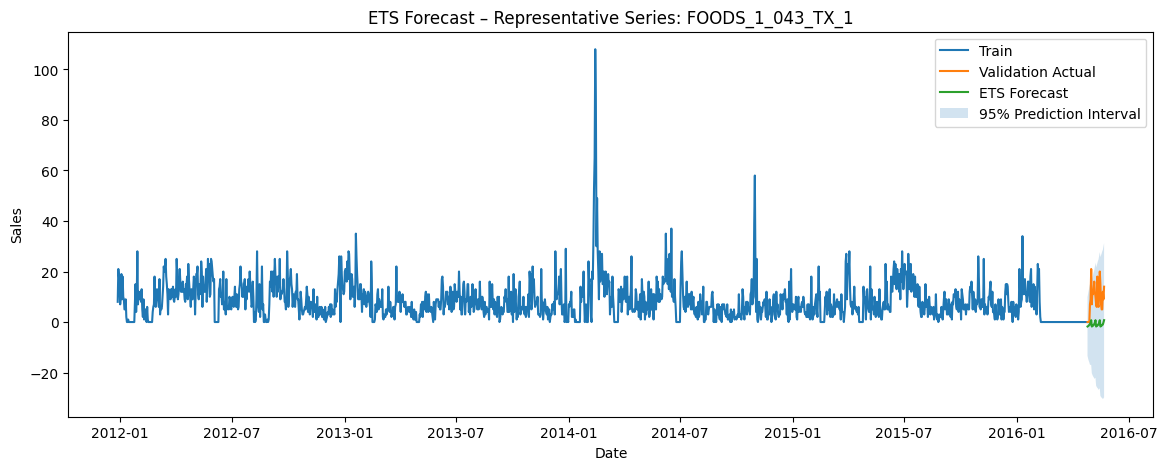

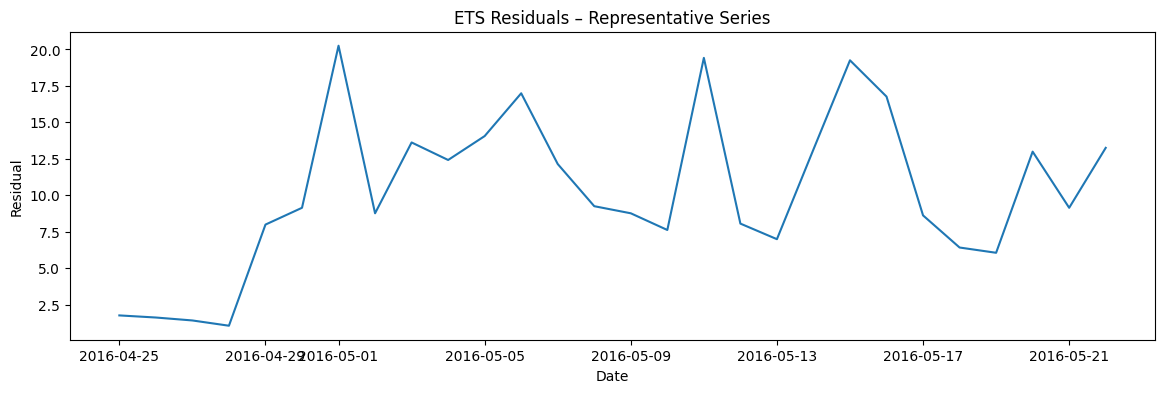

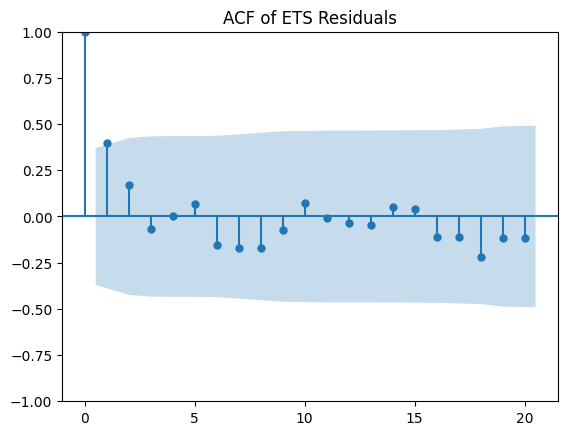

In [22]:
# Choose a representative series: highest mean sales in training
representative_id = (
    train_main.groupby("unique_id")["y"]
    .mean()
    .sort_values(ascending=False)
    .index[0]
)

plot_df = train_main[train_main["unique_id"] == representative_id].copy()
val_plot = val[val["unique_id"] == representative_id].copy()
fcst_plot = fcst_ets_val[fcst_ets_val["unique_id"] == representative_id].copy()

plt.figure(figsize=(14, 5))
plt.plot(plot_df["ds"], plot_df["y"], label="Train")
plt.plot(val_plot["ds"], val_plot["y"], label="Validation Actual")
plt.plot(fcst_plot["ds"], fcst_plot["AutoETS"], label="ETS Forecast")

if "AutoETS-lo-95" in fcst_plot.columns and "AutoETS-hi-95" in fcst_plot.columns:
    plt.fill_between(
        fcst_plot["ds"],
        fcst_plot["AutoETS-lo-95"],
        fcst_plot["AutoETS-hi-95"],
        alpha=0.2,
        label="95% Prediction Interval"
    )

plt.title(f"ETS Forecast – Representative Series: {representative_id}")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.legend()
plt.show()

diag_df = ets_eval_df[ets_eval_df["unique_id"] == representative_id].copy()
diag_df["residual"] = diag_df["y"] - diag_df["AutoETS"]

plt.figure(figsize=(14, 4))
plt.plot(diag_df["ds"], diag_df["residual"])
plt.title("ETS Residuals – Representative Series")
plt.xlabel("Date")
plt.ylabel("Residual")
plt.show()

plot_acf(diag_df["residual"], lags=min(20, len(diag_df["residual"]) - 1))
plt.title("ACF of ETS Residuals")
plt.show()

## 7.Model Interpretation

At this stage, the interpretation should focus on whether ETS:

- improves over the baseline models,
- narrows the error relative to ARIMA-based approaches,
- captures the weekly seasonal structure adequately.

If ETS performs similarly to Seasonal Naive, that suggests the time series is strongly driven by recurring weekly patterns.  
If ETS performs better, this indicates that explicit modelling of level, trend, and seasonality adds meaningful predictive value.

In [23]:
try:
    print("Selected ETS model details:")
    print(sf_ets.fitted_[0, 0].model_)
except Exception as e:
    print("Model internals could not be displayed in this environment:", e)

Selected ETS model details:
{'loglik': -7736.911229989542, 'aic': 15479.822459979085, 'bic': np.float64(15496.490175259918), 'aicc': 15479.835038595436, 'mse': np.float64(1.7110347167624853), 'amse': np.float64(1.7111715274986359), 'fit': results(x=array([0.02001284, 0.51013129]), fn=15473.822459979085, nit=30, simplex=array([[0.02001284, 0.51013129],
       [0.02008292, 0.51064484],
       [0.02005426, 0.51236959]])), 'residuals': array([ 0.48986871,  0.48006505, -0.52954242, ..., -0.3884816 ,
       -0.38070698, -0.37308795]), 'components': 'ANNN', 'm': 1, 'nstate': 1, 'fitted': array([0.51013129, 0.51993495, 0.52954242, ..., 0.3884816 , 0.38070698,
       0.37308795]), 'states': array([[0.51013129],
       [0.51993495],
       [0.52954242],
       ...,
       [0.38070698],
       [0.37308795],
       [0.3656214 ]]), 'par': array([0.02001284,        nan,        nan,        nan, 0.51013129]), 'sigma2': np.float64(1.7146217916403954), 'n_params': 3, 'method': 'ETS(A,N,N)', 'actual_resi

## 8.Consolidate Results with Baselines and ARIMA

This is the key step that connects the entire statistical modelling pipeline.

The notebook attempts to read:
1. `statistical_results_until_autoarima.csv` (preferred consolidated file);
2. otherwise, it falls back to combining `baseline_metrics.csv` and `autoarima_metrics.csv`.

The final output is a unified table containing:
- Baselines
- ARIMA / AutoARIMA
- ETS

In [24]:
drive_results_path = f"{BASE_PATH}/statistical_results_until_autoarima.csv"
local_results_path = "statistical_results_until_autoarima.csv"

if os.path.exists(drive_results_path):
    previous_results = pd.read_csv(drive_results_path)
    print("Loaded consolidated results from ARIMA notebook (Google Drive).")
elif os.path.exists(local_results_path):
    previous_results = pd.read_csv(local_results_path)
    print("Loaded consolidated results from ARIMA notebook (local working directory).")
else:
    parts = []
    drive_baseline = f"{BASE_PATH}/baseline_metrics.csv"
    drive_auto = f"{BASE_PATH}/autoarima_metrics.csv"
    if os.path.exists(drive_baseline):
        parts.append(pd.read_csv(drive_baseline))
        print("Loaded baseline_metrics.csv from Google Drive")
    elif os.path.exists("baseline_metrics.csv"):
        parts.append(pd.read_csv("baseline_metrics.csv"))
        print("Loaded baseline_metrics.csv from local working directory")
    if os.path.exists(drive_auto):
        parts.append(pd.read_csv(drive_auto))
        print("Loaded autoarima_metrics.csv from Google Drive")
    elif os.path.exists("autoarima_metrics.csv"):
        parts.append(pd.read_csv("autoarima_metrics.csv"))
        print("Loaded autoarima_metrics.csv from local working directory")

    if len(parts) == 0:
        raise FileNotFoundError(
            "No previous metrics file found in Google Drive or local storage. Please ensure the ARIMA notebook exported its results first."
        )
    previous_results = pd.concat(parts, ignore_index=True)

# Standardise column names if needed
expected_cols = {"Model", "MAE", "RMSE", "RMSSE"}
missing_cols = expected_cols - set(previous_results.columns)
if missing_cols:
    raise ValueError(f"Previous results file is missing columns: {missing_cols}")

final_results = pd.concat([previous_results, ets_metrics_df], ignore_index=True)
final_results = final_results.drop_duplicates(subset=["Model"], keep="last")
final_results = final_results.sort_values("RMSSE").reset_index(drop=True)

print("Final statistical results:")
display(final_results)


Loaded consolidated results from ARIMA notebook (Google Drive).
Final statistical results:


,Model,MAE,RMSE,RMSSE
0,AutoARIMAX,1.020621,1.787901,0.744276
1,AutoETS,1.063430,2.053841,0.745743
2,AutoARIMA,1.034439,1.874169,0.749979
3,HistoricAverage,1.098873,1.881901,0.763119
4,Naive,1.258598,2.439411,0.940938
5,RWD,1.272988,2.453267,0.946122
6,SeasonalNaive,1.226852,2.438055,0.955998


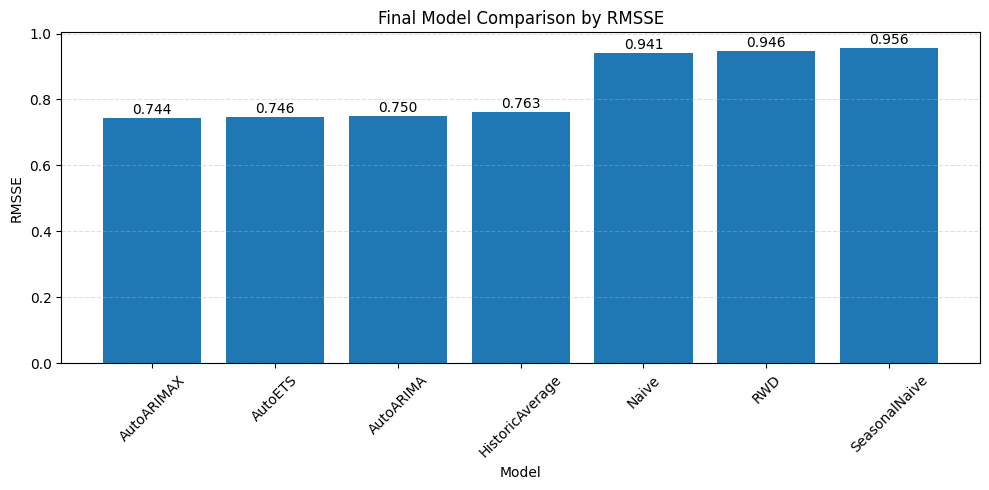

In [26]:
plot_df = final_results.sort_values("RMSSE").copy()

plt.figure(figsize=(10, 5))
bars = plt.bar(plot_df["Model"], plot_df["RMSSE"])
plt.title("Final Model Comparison by RMSSE")
plt.xlabel("Model")
plt.ylabel("RMSSE")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)

for bar, value in zip(bars, plot_df["RMSSE"]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value + 0.003,
        f"{value:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



The following table summarises the performance of all statistical models developed throughout this project.

Although multiple metrics are presented, RMSSE is used as the main benchmark for comparison, as it is specifically designed for the M5 competition setting and provides a scale-independent evaluation across multiple time series.

For this reason, the final ranking and model selection are primarily based on RMSSE.

In [25]:
# Export ETS outputs for documentation and reproducibility
ets_metrics_df.to_csv("ets_metrics.csv", index=False)
fcst_ets_val.to_csv("ets_forecasts_val.csv", index=False)
final_results.to_csv("final_statistical_results.csv", index=False)

ets_metrics_df.to_csv(f"{BASE_PATH}/ets_metrics.csv", index=False)
fcst_ets_val.to_csv(f"{BASE_PATH}/ets_forecasts_val.csv", index=False)
final_results.to_csv(f"{BASE_PATH}/final_statistical_results.csv", index=False)

print("Files exported successfully:")
print("- ets_metrics.csv")
print("- ets_forecasts_val.csv")
print("- final_statistical_results.csv")
print(f"Files also saved to: {BASE_PATH}")


Files exported successfully:
- ets_metrics.csv
- ets_forecasts_val.csv
- final_statistical_results.csv
Files also saved to: /content/drive/MyDrive/m5_project


## 9.Final Interpretation and Conclusion

This notebook completes the statistical forecasting pipeline by adding the ETS model to the comparison of baseline and autoregressive approaches.

The final results show that all advanced statistical models (AutoARIMA, AutoARIMAX, and AutoETS) clearly outperform the baseline methods, confirming the importance of modeling temporal dependencies in retail demand data.

Among the models, **AutoARIMAX achieves the best overall performance**, followed very closely by **AutoETS**, and then **AutoARIMA**. The small differences between these models indicate that most of the predictive signal is already captured by the intrinsic time series structure, particularly autocorrelation and weekly seasonality.

Although the inclusion of exogenous regressors provides the top result, the improvement over the univariate and ETS models is relatively modest. This suggests that external factors such as calendar effects, SNAP, prices, and events contribute additional information, but their impact is limited compared to the strong internal dynamics of the series.

From a practical perspective, these findings indicate that:
- simple baseline models are insufficient for accurate forecasting,
- both autoregressive and exponential smoothing approaches provide strong performance,
- and the marginal gains from additional complexity should be carefully weighed against model simplicity.

Overall, **AutoARIMAX is selected as the best-performing statistical model**, while **AutoETS stands out as a highly competitive and robust alternative**, achieving nearly identical performance without requiring external regressors.

This completes the statistical modeling stage and provides a solid foundation for further modeling approaches or deployment considerations.